In [1]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importamos nuestro módulo de ML
ml = importlib.import_module("flows.05_ml_models")
sns.set_theme(style="whitegrid", context="notebook")

# Cargamos el dataset formulado
X, y = ml.load_dataset()
print("Dimensiones de X:", X.shape)
print("Tasa de supervivencia (y.mean()):", round(y.mean(), 4))

Dimensiones de X: (891, 12)
Tasa de supervivencia (y.mean()): 0.3838


# Formulación del Problema de Machine Learning (Paso 39)

| Decisión | Tu respuesta |
| :--- | :--- |
| **Tipo de problema** | Clasificación binaria supervisada |
| **Variable objetivo** | `Survived` (1 = sobrevivió) |
| **Unidad de análisis y momento de predicción** | Un pasajero, *al embarcar* |
| **Métrica principal** | ROC-AUC, porque evalúa la capacidad de discriminación sin depender de un umbral de decisión rígido en un entorno desbalanceado (~38% positivos). |
| **Métricas secundarias** | precisión, recall, exactitud, F1-score |
| **Costo de errores** | Para una aseguradora, predecir falsamente que alguien sobrevive genera un riesgo financiero crítico de estimación; predecir que muere representa una oportunidad comercial perdida. |
| **Criterio de éxito** | Superar el baseline por un margen que puedas defender |


## Paso 40. Auditoría de variables y fuga de datos

| Columna | ¿Existe antes del evento? | ¿Riesgo de fuga? | Decisión |
| :--- | :--- | :--- | :--- |
| `Survived`, `Survivor` | No (es el objetivo) | **Fuga directa** | **Excluir** |
| `PassengerId`, `Ticket`, `Name` | Sí | Identificadores: memorizan, no generalizan | **Excluir** (el título sí, vía `TTitulo`) |
| `NSex`, `NEmbarked`, `NCabin`, `NTitulo` | — | Duplican a `Sex`, etc. con un orden arbitrario | **Excluir** (usar *one-hot*) |
| `Age` imputada | — | Estadística calculada con todos los datos | **Usar `AgeOriginal`** |
| `Cabin`, `TCabin`, `HasCabin` | **Dudoso** | ¿Se registró la cabina *después* del naufragio (más fácil para los sobrevivientes)? | **Evaluar con y sin ella** (Paso 61) |
| `Person` | Derivada de Age / Sex | Redundante con ambas | **Excluir del modelo base** |

**Reflexión sobre el debate de `HasCabin`:**
Si `HasCabin` mejora la métrica de predicción, no significa necesariamente que tener cabina otorgue una ventaja física de supervivencia. Existe un **artefacto de registro**: la información de la cabina se conservó y documentó con mayor precisión para los pasajeros que sobrevivieron y pudieron dar testimonio, inflando artificialmente el valor predictivo de esta variable. Un modelo robusto debe evaluar este tipo de variables con cautela para no aprender sesgos burocráticos en lugar de riesgo real.

In [4]:
import importlib

# Como el archivo empieza con número, se importa estrictamente con importlib:
ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# Cargamos el dataset y realizamos la división estratificada
X, y = ml.load_dataset()
X_train, X_test, y_train, y_test = ml.split(X, y)

print("Dimensiones de Train:", X_train.shape)
print("Dimensiones de Test:", X_test.shape)
print("-" * 40)
print("Tasa de supervivencia en Train:", round(y_train.mean(), 4))
print("Tasa de supervivencia en Test: ", round(y_test.mean(), 4))

Dimensiones de Train: (712, 12)
Dimensiones de Test: (179, 12)
----------------------------------------
Tasa de supervivencia en Train: 0.3834
Tasa de supervivencia en Test:  0.3855


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# --- 1. Baseline "Ingenuo" (DummyClassifier) ---
dummy = DummyClassifier(strategy='most_frequent', random_state=42)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_train)

print("=== Baseline 1: DummyClassifier (Clase Mayoritaria) ===")
print(f"Exactitud (Accuracy): {accuracy_score(y_train, y_pred_dummy):.4f}")
print("-" * 50)

# --- 2. Baseline "Regla de Género" (Mujeres sobreviven, hombres no) ---
# Predice 1 si Sex == 'female', 0 en caso contrario
y_pred_gender = (X_train['Sex'] == 'female').astype(int)

acc_g = accuracy_score(y_train, y_pred_gender)
prec_g = precision_score(y_train, y_pred_gender)
rec_g = recall_score(y_train, y_pred_gender)
f1_g = f1_score(y_train, y_pred_gender)

print("=== Baseline 2: Regla de Género (Sex == 'female') ===")
print(f"Exactitud (Accuracy): {acc_g:.4f}  (Debería rondar ~0.79)")
print(f"Precisión:            {prec_g:.4f}")
print(f"Recall (Sensibilidad): {rec_g:.4f}")
print(f"F1-score:             {f1_g:.4f}")

=== Baseline 1: DummyClassifier (Clase Mayoritaria) ===
Exactitud (Accuracy): 0.6166
--------------------------------------------------
=== Baseline 2: Regla de Género (Sex == 'female') ===
Exactitud (Accuracy): 0.7893  (Debería rondar ~0.79)
Precisión:            0.7431
Recall (Sensibilidad): 0.6886
F1-score:             0.7148


In [6]:
# --- Paso 43: Experimento de Fuga de Datos (Data Leakage) ---

# 1. Edad media de las mujeres usando TODO el dataset (X)
# (Esto simula el error de imputar o calcular estadísticas antes del split)
age_mean_all = X[X['Sex'] == 'female']['Age'].mean()

# 2. Edad media de las mujeres usando SOLO el conjunto de entrenamiento (X_train)
# (Esto es lo correcto: el test set permanece completamente ciego)
age_mean_train = X_train[X_train['Sex'] == 'female']['Age'].mean()

print(f"Edad media mujeres (TODO el dataset X):  {age_mean_all:.4f}")
print(f"Edad media mujeres (SOLO X_train):      {age_mean_train:.4f}")
print(f"Diferencia absoluta:                  {abs(age_mean_all - age_mean_train):.4f}")

Edad media mujeres (TODO el dataset X):  27.9157
Edad media mujeres (SOLO X_train):      28.1834
Diferencia absoluta:                  0.2677


**Reflexión del experimento de Fuga de Datos (Paso 43):**
1. **¿Qué información viajó?** Información estadística sobre la distribución de la edad del conjunto de prueba (`X_test`) se filtró prematuramente hacia los cálculos de entrenamiento al usar todo el dataset.
2. **¿Por qué la diferencia es pequeña y por qué es un error?** La diferencia es pequeña aquí por el gran tamaño de la muestra y la estabilidad del Titanic, pero metodológicamente es un error grave: en otros datasets con muestras pequeñas o alta proporción de nulos, esta filtración infla artificialmente el rendimiento del modelo y destruye su capacidad de generalización real.

In [7]:
import importlib
ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# Cargamos los datos y construimos el preprocesador
X, y = ml.load_dataset()
X_train, X_test, y_train, y_test = ml.split(X, y)

preprocessor = ml.build_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train)

print("Dimensiones de X_train después del ColumnTransformer:", X_train_transformed.shape)

Dimensiones de X_train después del ColumnTransformer: (712, 19)


In [8]:
import importlib
from sklearn.linear_model import LogisticRegression

ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# Creamos un modelo de prueba (Regresión Logística)
clf = LogisticRegression(random_state=42)

# Construimos el pipeline completo
pipeline = ml.build_pipeline(clf)

# Probamos ajustar el pipeline con X_train e y_train
pipeline.fit(X_train, y_train)

# Predicción de prueba
score = pipeline.score(X_train, y_train)
print(f"Precisión del Pipeline con Regresión Logística en Train: {score:.4f}")

Precisión del Pipeline con Regresión Logística en Train: 0.8048


In [9]:
from sklearn.dummy import DummyClassifier
import numpy as np

# 1. Construir pipeline con DummyClassifier y extraer solo el preprocesador entrenado en X_train
pipe = ml.build_pipeline(DummyClassifier())
pre = pipe[:-1].fit(X_train)

# 2. Transformar X_test y verificar que no queden NaNs
Z = pre.transform(X_test)
print("¿Hay valores NaN en Z (X_test transformado)?:", np.isnan(Z).any())
print("Número total de columnas resultantes:", Z.shape[1])

# 3. Obtener los nombres de las columnas resultantes
feature_names = pre['prep'].get_feature_names_out()
print("\nPrimeras 5 columnas:", feature_names[:5])

# 4. Comprobar que 'Sex' quedó codificado como cat__Sex_female / cat__Sex_male
sex_cols = [col for col in feature_names if 'Sex' in col]
print("\nColumnas generadas para 'Sex':", sex_cols)

¿Hay valores NaN en Z (X_test transformado)?: False
Número total de columnas resultantes: 19

Primeras 5 columnas: ['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'num__Familia']

Columnas generadas para 'Sex': ['cat__Sex_female', 'cat__Sex_male']


In [10]:
# Recargamos el módulo
import importlib
ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

# Ejecutamos la validación cruzada en el conjunto de entrenamiento
df_cv_results = ml.cross_validate_candidates(X_train, y_train)

# 1. Muestra la tabla de resultados resumida enfocada en la métrica principal y accuracy
cols_to_show = [col for col in df_cv_results.columns if 'mean' in col or col == 'model']
df_cv_results[cols_to_show]

/home/darkness/proyectos/proyecto_ciencia_de_datos/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/darkness/proyectos/proyecto_ciencia_de_datos/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/darkness/proyectos/proyecto_ciencia_de_datos/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.


,model,test_accuracy_mean,train_accuracy_mean,test_precision_mean,train_precision_mean,test_recall_mean,train_recall_mean,test_f1_mean,train_f1_mean,test_roc_auc_mean,train_roc_auc_mean
0,hgb,0.814616,0.953655,0.793801,0.960636,0.703300,0.916673,0.744672,0.938105,0.881790,0.992684
1,forest,0.794957,0.983849,0.740595,0.984305,0.717845,0.973441,0.728445,0.978825,0.865347,0.998149
2,logreg,0.799173,0.807934,0.757587,0.775810,0.703434,0.702388,0.728608,0.737182,0.856929,0.863358
3,tree,0.810411,0.846905,0.819567,0.887360,0.651987,0.691379,0.723701,0.776051,0.847480,0.892679
4,knn,0.789353,0.851477,0.754429,0.836989,0.674007,0.761011,0.710844,0.797043,0.837465,0.926769
5,dummy,0.616576,0.616573,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.500000


In [11]:
# Calculamos la brecha de ROC-AUC (Train - Test) para cada modelo
df_cv_results['gap_roc_auc'] = df_cv_results['train_roc_auc_mean'] - df_cv_results['test_roc_auc_mean']

# Mostramos un resumen con modelo, AUC en test, desviación y la brecha
df_cv_results[['model', 'test_roc_auc_mean', 'test_roc_auc_std', 'gap_roc_auc']]

,model,test_roc_auc_mean,test_roc_auc_std,gap_roc_auc
0,hgb,0.881790,0.020788,0.110893
1,forest,0.865347,0.012788,0.132803
2,logreg,0.856929,0.022541,0.006429
3,tree,0.847480,0.025624,0.045199
4,knn,0.837465,0.017681,0.089304
5,dummy,0.500000,0.000000,0.000000


Reporte de Clasificación (Fuera de Muestra - Out-of-Fold):
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       439
           1       0.76      0.70      0.73       273

    accuracy                           0.80       712
   macro avg       0.79      0.78      0.78       712
weighted avg       0.80      0.80      0.80       712



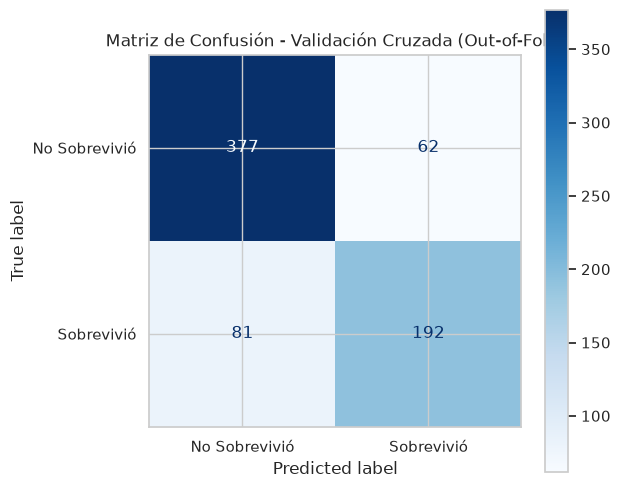

In [13]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# 1. Definimos el esquema de validación cruzada estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=getattr(ml.settings, "RANDOM_STATE", 42))

# 2. Seleccionamos el modelo finalista ('logreg') y construimos su pipeline completo
modelo_elegido = ml.get_candidates(42)["logreg"]
pipe_finalista = ml.build_pipeline(modelo_elegido)

# 3. Obtenemos las probabilidades fuera de muestra (out-of-fold) para la clase positiva
proba_oof = cross_val_predict(pipe_finalista, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

# 4. Convertimos las probabilidades en clases binarias usando un umbral de 0.5
pred_oof = (proba_oof >= 0.5).astype(int)

# 5. Imprimimos el reporte de clasificación detallado
print("Reporte de Clasificación (Fuera de Muestra - Out-of-Fold):")
print(classification_report(y_train, pred_oof))

# 6. Generamos y mostramos la Matriz de Confusión visualmente (Corregido: display_labels)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train, pred_oof, ax=ax, cmap="Blues", display_labels=["No Sobrevivió", "Sobrevivió"]
)
plt.title("Matriz de Confusión - Validación Cruzada (Out-of-Fold)")
plt.show()

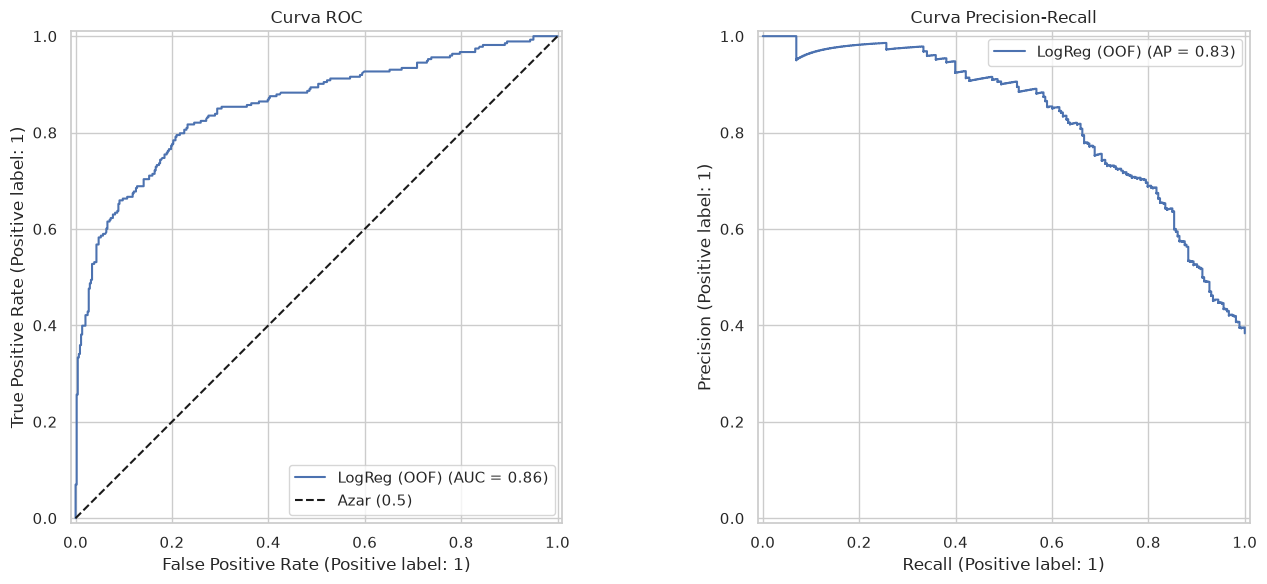

In [14]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Curva ROC
RocCurveDisplay.from_predictions(y_train, proba_oof, name="LogReg (OOF)", ax=axes[0])
axes[0].set_title("Curva ROC")
axes[0].plot([0, 1], [0, 1], "k--", label="Azar (0.5)")
axes[0].legend()

# 2. Curva Precision-Recall
PrecisionRecallDisplay.from_predictions(y_train, proba_oof, name="LogReg (OOF)", ax=axes[1])
axes[1].set_title("Curva Precision-Recall")
axes[1].legend()

plt.tight_layout()
plt.show()

Brier Score (cercano a 0 es mejor, azar ~0.25): 0.1400


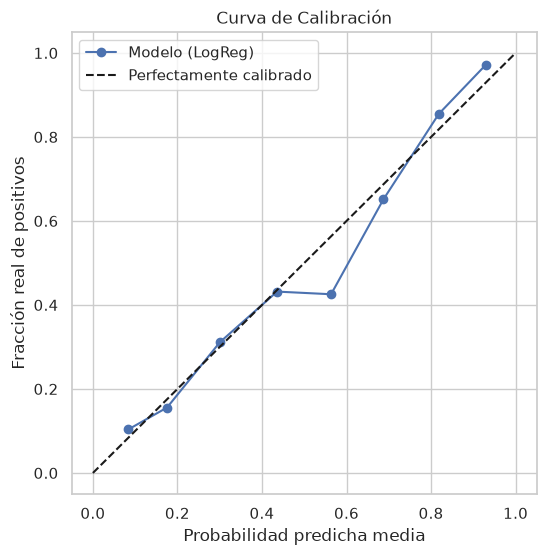


Umbral óptimo basado en F1-Score: 0.2998
Mejor F1-Score alcanzado: 0.7458


In [15]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, precision_recall_curve
import numpy as np

# 1. Curva de calibración y Brier Score
brier = brier_score_loss(y_train, proba_oof)
print(f"Brier Score (cercano a 0 es mejor, azar ~0.25): {brier:.4f}")

prob_true, prob_pred = calibration_curve(y_train, proba_oof, n_bins=8)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(prob_pred, prob_true, marker='o', label='Modelo (LogReg)')
ax.plot([0, 1], [0, 1], 'k--', label='Perfectamente calibrado')
ax.set_xlabel("Probabilidad predicha media")
ax.set_ylabel("Fracción real de positivos")
ax.set_title("Curva de Calibración")
ax.legend()
plt.show()

# 3. Encontrar el umbral óptimo que maximiza F1
precision, recall, thresholds = precision_recall_curve(y_train, proba_oof)
# Evitamos división por cero calculando F1 para cada umbral
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"\nUmbral óptimo basado en F1-Score: {best_threshold:.4f}")
print(f"Mejor F1-Score alcanzado: {f1_scores[best_idx]:.4f}")

In [16]:
import pandas as pd

# 1. Construir un DataFrame de auditoría con X_train, y_train, predicciones y errores
df_audit = X_train.copy()
df_audit["Target"] = y_train.values
df_audit["Proba_OOF"] = proba_oof
# Usamos el umbral óptimo de 0.30 que hallamos antes (o 0.5 por defecto)
optimal_threshold = 0.30
df_audit["Pred_OOF"] = (df_audit["Proba_OOF"] >= optimal_threshold).astype(int)
df_audit["Error"] = df_audit["Target"] != df_audit["Pred_OOF"]

# 2. Calcular exactitud y rendimiento por subgrupo (ej. Sex y Pclass)
print("--- Error por Sexo ---")
print(df_audit.groupby("Sex")["Error"].mean())

print("\n--- Error por Clase (Pclass) ---")
print(df_audit.groupby("Pclass")["Error"].mean())

# 4. Examinar 10 errores concretos de alta confianza (probabilidad muy alta o muy baja pero equivocados)
print("\n--- Top 10 Errores de Alta Confianza ---")
errores_altos = df_audit[df_audit["Error"]].copy()
# Distancia al umbral (qué tan seguro estaba el modelo)
errores_altos["Confianza_Error"] = abs(errores_altos["Proba_OOF"] - optimal_threshold)
top_errores = errores_altos.sort_values(by="Confianza_Error", ascending=False).head(10)
display(top_errores[["Age", "Sex", "Pclass", "Fare", "Target", "Proba_OOF", "Pred_OOF"]])

--- Error por Sexo ---
Sex
female    0.241107
male      0.200436
Name: Error, dtype: float64

--- Error por Clase (Pclass) ---
Pclass
1    0.263158
2    0.120000
3    0.230179
Name: Error, dtype: float64

--- Top 10 Errores de Alta Confianza ---


,Age,Sex,Pclass,Fare,Target,Proba_OOF,Pred_OOF
498,25.0,female,1,151.5500,0,0.946398,1
41,27.0,female,2,21.0000,0,0.876472,1
118,24.0,male,1,247.5208,0,0.848229,1
312,26.0,female,2,26.0000,0,0.845696,1
205,2.0,female,3,10.4625,0,0.822678,1
654,18.0,female,3,6.7500,0,0.808235,1
49,18.0,female,3,17.8000,0,0.800588,1
177,50.0,female,1,28.7125,0,0.798876,1
854,44.0,female,2,26.0000,0,0.798445,1
657,32.0,female,3,15.5000,0,0.782116,1


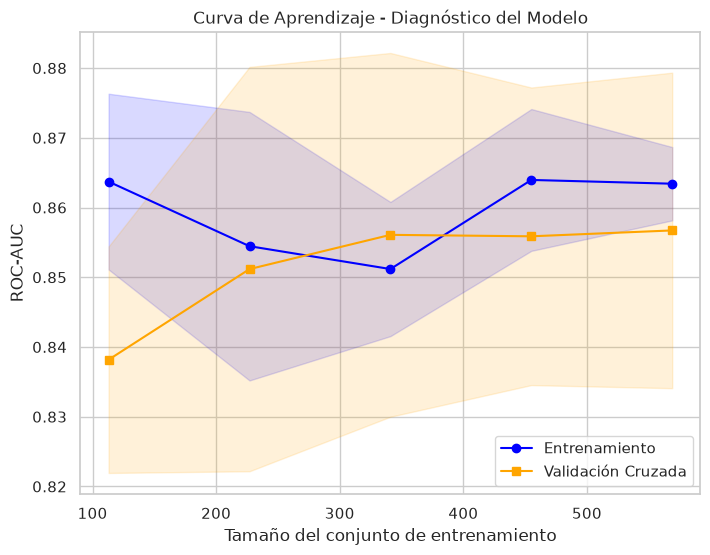

In [17]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# 1. Calcular la curva de aprendizaje
train_sizes, train_scores, val_scores = learning_curve(
    pipe_finalista, 
    X_train, 
    y_train, 
    cv=cv, 
    train_sizes=np.linspace(0.2, 1.0, 5), 
    scoring='roc_auc',
    n_jobs=-1
)

# 2. Calcular medias y desviaciones estándar
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# 3. Graficar la curva de aprendizaje
plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_mean, label='Entrenamiento', color='blue', marker='o')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='blue', alpha=0.15)

plt.plot(train_sizes, val_mean, label='Validación Cruzada', color='orange', marker='s')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color='orange', alpha=0.15)

plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("ROC-AUC")
plt.title("Curva de Aprendizaje - Diagnóstico del Modelo")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [19]:
import importlib
ml = importlib.import_module("flows.05_ml_models")
importlib.reload(ml)

<module 'flows.05_ml_models' from '/home/darkness/proyectos/proyecto_ciencia_de_datos/flows/05_ml_models.py'>

In [20]:
from sklearn.model_selection import GridSearchCV
import pandas as pd

# Obtenemos los diccionarios de modelos y sus respectivas rejillas de parámetros
candidates = ml.get_candidates(42)
param_grids = ml.get_param_grids()

best_models = {}
cv_grid_reports = {}

for name, model in candidates.items():
    # Solo optimizamos los modelos que tienen una rejilla de parámetros definida
    if name not in param_grids:
        continue
        
    print(f"\n==========================================")
    print(f"Optimizando hiperparámetros para: {name}")
    print(f"==========================================")
    
    grid = param_grids[name]
    pipe = ml.build_pipeline(model)
    
    # 1. Configurar GridSearchCV con la métrica principal ('roc_auc') y validación cruzada
    gs = GridSearchCV(
        estimator=pipe,
        param_grid=grid,
        scoring=ml.PRIMARY_METRIC,
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    
    # 2. Ajustar el GridSearch SOLO con datos de entrenamiento
    gs.fit(X_train, y_train)
    
    # 3. Guardar el mejor estimador y mostrar resultados clave
    best_models[name] = gs.best_estimator_
    print(f"Mejores parámetros: {gs.best_params_}")
    print(f"Mejor ROC-AUC en CV: {gs.best_score_:.4f}")
    
    # 4. Convertir cv_results_ a DataFrame ordenado por el ranking de desempeño
    df_results = pd.DataFrame(gs.cv_results_)
    cv_grid_reports[name] = df_results.sort_values(by="rank_test_score")


Optimizando hiperparámetros para: logreg


/home/darkness/proyectos/proyecto_ciencia_de_datos/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/darkness/proyectos/proyecto_ciencia_de_datos/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penal

Mejores parámetros: {'model__C': 10, 'model__penalty': 'l2'}
Mejor ROC-AUC en CV: 0.8569

Optimizando hiperparámetros para: forest
Mejores parámetros: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}
Mejor ROC-AUC en CV: 0.8788

Optimizando hiperparámetros para: hgb
Mejores parámetros: {'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__max_iter': 200}
Mejor ROC-AUC en CV: 0.8913


In [22]:
from sklearn.model_selection import cross_val_score
import numpy as np
import pandas as pd

# Seleccionamos el modelo base y el pipeline ya ajustado del GridSearch ('gs.best_estimator_')
pipe_base = ml.build_pipeline(candidates["hgb"])
pipe_tuned = best_models["hgb"]  # Este ya es el pipeline completo optimizado por GridSearchCV

# Evaluamos ambos utilizando EXACTAMENTE el mismo objeto de validación cruzada (cv) y métrica ('roc_auc')
scores_base = cross_val_score(pipe_base, X_train, y_train, cv=cv, scoring=ml.PRIMARY_METRIC)
scores_tuned = cross_val_score(pipe_tuned, X_train, y_train, cv=cv, scoring=ml.PRIMARY_METRIC)

# Calculamos las diferencias pliegue a pliegue
diferencias = scores_tuned - scores_base

# Mostramos los resultados detallados
df_comparacion = pd.DataFrame({
    "Pliegue": [1, 2, 3, 4, 5],
    "Base (ROC-AUC)": scores_base,
    "Ajustado (ROC-AUC)": scores_tuned,
    "Diferencia (Ajustado - Base)": diferencias
})

display(df_comparacion)

print(f"\nMedia de la mejora: {diferencias.mean():.4f}")
print(f"Desviación estándar de las diferencias: {diferencias.std():.4f}")

,Pliegue,Base (ROC-AUC),Ajustado (ROC-AUC),Diferencia (Ajustado - Base)
0,1,0.895971,0.905579,0.009607
1,2,0.842045,0.854545,0.012500
2,3,0.900522,0.926541,0.026019
3,4,0.883523,0.873527,-0.009996
4,5,0.886890,0.896359,0.009470



Media de la mejora: 0.0095
Desviación estándar de las diferencias: 0.0115
